In [1]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
glass = fetch_ucirepo( id = 42 )
X = glass.data.features
y = glass.data.targets.values.ravel()


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

from sklearn.preprocessing import StandardScaler

zscore_scaler = StandardScaler()

X_train_std = zscore_scaler.fit_transform(X_train)
X_test_std = zscore_scaler.transform(X_test)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

grids = {
    "linear": {"kernel": ["linear"],
               "C": [0.01, 0.1, 1, 10, 100]},
    "poly":   {"kernel": ["poly"],
               "degree": [2, 3],
               "C": [0.1, 1, 10, 100],
               "gamma": ["scale", 0.01, 0.1, 1]},
    "rbf":    {"kernel": ["rbf"],
               "C": [0.1, 1, 10, 100],
               "gamma": ["scale", 0.01, 0.1, 1, 10]},
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
todas = []  # cv_results_ de cada busca, para o mapa de calor

for scaled in [False, True]:
    rotulo = "COM scaling" if scaled else "SEM scaling"
    Xtr = X_train_std if scaled else X_train
    Xte = X_test_std if scaled else X_test

    for kernel, grid in grids.items():
        search = GridSearchCV(SVC(), grid, cv=cv, scoring="accuracy",
                              n_jobs=-1, return_train_score=True)
        search.fit(Xtr, y_train)

        # Avaliação final no teste, uma única vez por modelo
        acc_test = accuracy_score(y_test, search.best_estimator_.predict(Xte))
        i = search.best_index_

        cvr = pd.DataFrame(search.cv_results_)
        cvr["pre"] = rotulo
        cvr["kernel_nome"] = kernel
        todas.append(cvr)

        resultados.append({
            "pre-processamento": rotulo,
            "kernel": kernel,
            "melhores params": {k: v for k, v in search.best_params_.items() if k != "kernel"},
            "acc CV (treino)": round(search.best_score_, 4),
            "acc CV desvio": round(search.cv_results_["std_test_score"][i], 4),
            "acc treino CV": round(search.cv_results_["mean_train_score"][i], 4),
            "acc teste": round(acc_test, 4),
        })

df = pd.DataFrame(resultados)
print(df.to_string(index=False))

pre-processamento kernel                        melhores params  acc CV (treino)  acc CV desvio  acc treino CV  acc teste
      SEM scaling linear                              {'C': 10}           0.6548         0.0636         0.7397     0.7209
      SEM scaling   poly {'C': 0.1, 'degree': 3, 'gamma': 0.01}           0.6897         0.0527         0.7587     0.7209
      SEM scaling    rbf                {'C': 10, 'gamma': 0.1}           0.6956         0.0455         0.8055     0.7209
      COM scaling linear                               {'C': 1}           0.6548         0.0688         0.7266     0.6977
      COM scaling   poly     {'C': 10, 'degree': 2, 'gamma': 1}           0.6371         0.1148         0.9473     0.7209
      COM scaling    rbf                 {'C': 1, 'gamma': 0.1}           0.6901         0.0395         0.7967     0.7209



Análise da validação cruzada:
pre-processamento kernel          acc CV  acc treino CV    gap  acc teste
      SEM scaling linear 0.6548 ± 0.0636         0.7397 0.0849     0.7209
      SEM scaling   poly 0.6897 ± 0.0527         0.7587 0.0690     0.7209
      SEM scaling    rbf 0.6956 ± 0.0455         0.8055 0.1099     0.7209
      COM scaling linear 0.6548 ± 0.0688         0.7266 0.0718     0.6977
      COM scaling   poly 0.6371 ± 0.1148         0.9473 0.3102     0.7209
      COM scaling    rbf 0.6901 ± 0.0395         0.7967 0.1066     0.7209


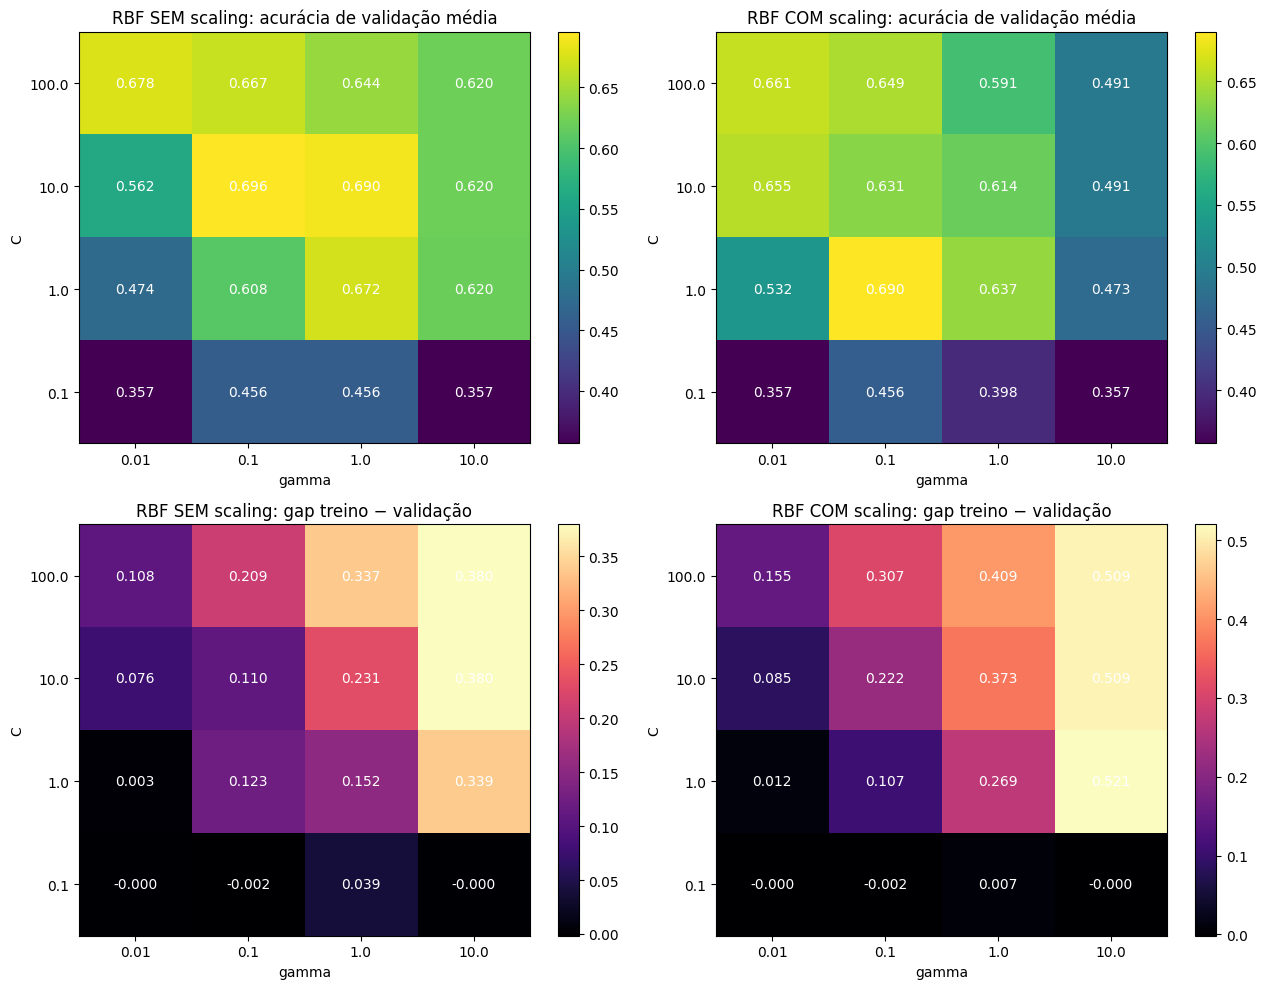

SEM scaling: melhor RBF com C=10.0, gamma=0.1, val=0.6956, gap=0.1099
COM scaling: melhor RBF com C=1.0, gamma=0.1, val=0.6901, gap=0.1067


In [4]:
# análise do cross-validation
df["acc CV"] = df.apply(lambda r: f"{r['acc CV (treino)']:.4f} ± {r['acc CV desvio']:.4f}", axis=1)
df["gap"] = (df["acc treino CV"] - df["acc CV (treino)"]).round(4)
print("\nAnálise da validação cruzada:")
print(df[["pre-processamento", "kernel", "acc CV", "acc treino CV", "gap", "acc teste"]]
      .to_string(index=False))

# mapa de calor do RBF: C x gamma numérico ('scale' fica de fora)
todos = pd.concat(todas, ignore_index=True)
rbf = todos[todos.kernel_nome == "rbf"].copy()
rbf = rbf[rbf.param_gamma.apply(lambda g: isinstance(g, (int, float)))].copy()
rbf["C"] = rbf.param_C.astype(float)
rbf["gamma"] = rbf.param_gamma.astype(float)
rbf["val"] = rbf.mean_test_score
rbf["gap"] = rbf.mean_train_score - rbf.mean_test_score

def heatmap(ax, mat, titulo, cmap, fmt):
    im = ax.imshow(mat.values, cmap=cmap, origin="lower", aspect="auto")
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
    ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title(titulo)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, format(mat.values[i, j], fmt), ha="center", va="center", color="w")
    plt.colorbar(im, ax=ax)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, pre in enumerate(["SEM scaling", "COM scaling"]):
    sub = rbf[rbf.pre == pre]
    val = sub.pivot(index="C", columns="gamma", values="val")
    gap = sub.pivot(index="C", columns="gamma", values="gap")
    heatmap(axes[0, col], val, f"RBF {pre}: acurácia de validação média", "viridis", ".3f")
    heatmap(axes[1, col], gap, f"RBF {pre}: gap treino − validação", "magma", ".3f")
plt.tight_layout()
plt.show()

for pre in ["SEM scaling", "COM scaling"]:
    sub = rbf[rbf.pre == pre]
    b = sub.loc[sub.val.idxmax()]
    print(f"{pre}: melhor RBF com C={b.C}, gamma={b.gamma}, val={b.val:.4f}, gap={b.gap:.4f}")

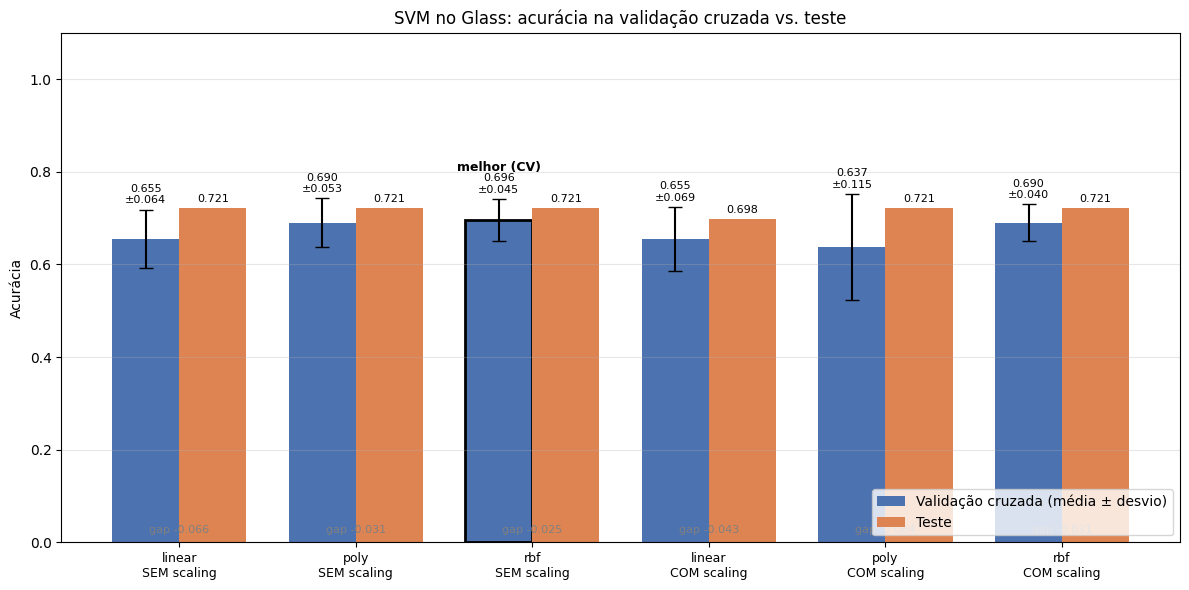

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# No código acima, "acc CV (treino)" guarda best_score_, que é a acurácia de VALIDAÇÃO
d = df.rename(columns={"acc CV (treino)": "acc CV (validação)"}).reset_index(drop=True)
d["modelo"] = d["kernel"] + "\n" + d["pre-processamento"]

x = np.arange(len(d))
w = 0.38
idx_best = d["acc CV (validação)"].idxmax()  # escolha pela validação, nunca pelo teste

fig, ax = plt.subplots(figsize=(12, 6))
b_cv = ax.bar(x - w/2, d["acc CV (validação)"], w,
              yerr=d["acc CV desvio"], capsize=5,
              color="#4C72B0", label="Validação cruzada (média ± desvio)")
b_te = ax.bar(x + w/2, d["acc teste"], w,
              color="#DD8452", label="Teste")

for i, row in d.iterrows():
    ax.annotate(f"{row['acc CV (validação)']:.3f}\n±{row['acc CV desvio']:.3f}",
                (x[i] - w/2, row["acc CV (validação)"] + row["acc CV desvio"]),
                ha="center", va="bottom", fontsize=8, xytext=(0, 3),
                textcoords="offset points")
    ax.annotate(f"{row['acc teste']:.3f}",
                (x[i] + w/2, row["acc teste"]),
                ha="center", va="bottom", fontsize=8, xytext=(0, 3),
                textcoords="offset points")
    gap = row["acc CV (validação)"] - row["acc teste"]
    ax.text(x[i], 0.02, f"gap {gap:+.3f}", ha="center", fontsize=8, color="gray")

# Destaque do melhor modelo pela validação
b_cv[idx_best].set_edgecolor("black")
b_cv[idx_best].set_linewidth(2)
ax.text(x[idx_best] - w/2,
        d.loc[idx_best, "acc CV (validação)"] + d.loc[idx_best, "acc CV desvio"] + 0.06,
        "melhor (CV)", ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(d["modelo"], fontsize=9)
ax.set_ylabel("Acurácia")
ax.set_ylim(0, 1.1)
ax.set_title("SVM no Glass: acurácia na validação cruzada vs. teste")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()